In [2]:
import numpy as np
import networkx as nx
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import time
import blockdynamicnetworks as bdn
import numpy as np
import pickle
import time
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "lines.linewidth": 2,
    "lines.markersize": 7,
    "text.usetex": False})

## Definition of scenarios

In [37]:
def generate_sbm(sizes, P, seed=None):
    rng = np.random.default_rng(seed)
    sizes = np.asarray(sizes, dtype=int)
    K = len(sizes)
    n = sizes.sum()
    z_true = np.repeat(np.arange(K), sizes)
    Y = np.zeros((n, n), dtype=np.int64)
    for i in range(n):
        for j in range(i + 1, n):
            p_ij = P[z_true[i], z_true[j]]
            Y[i, j] = rng.binomial(1, p_ij)
            Y[j, i] = Y[i, j]
    G = nx.from_numpy_array(Y)
    nx.set_node_attributes(G, {i: int(z_true[i]) for i in range(n)}, "block")
    return G, Y, z_true
n = 50
sizes = [10, 5, 13, 15, 7]
K = len(sizes)
assert sum(sizes) == n
def pattern_horizontal():
    P = np.full((5, 5), 0.25)
    np.fill_diagonal(P, 0.75)
    return P
def pattern_vertical():
    P = np.full((5, 5), 0.25)
    pairs = [(0, 1), (2, 3), (1, 4), (3, 4)]
    for a, b in pairs:
        P[a, b] = P[b, a] = 0.75
    np.fill_diagonal(P, 0.75)
    return P
def pattern_mixed():
    P = np.full((5, 5), 0.25)
    pairs = [(0, 2), (1, 3), (2, 3), (2, 4), (3, 4)]
    for a, b in pairs:
        P[a, b] = P[b, a] = 0.75
    np.fill_diagonal(P, 0.75)
    return P
patterns = {"Horizontal": pattern_horizontal(), "Vertical": pattern_vertical(), "Mixed": pattern_mixed()}
def transform_probabilities(P_base, p_in, p_out):
    P_new = np.empty_like(P_base, dtype=float)
    for i in range(P_base.shape[0]):
        for j in range(P_base.shape[1]):
            if i == j:
                P_new[i, j] = p_in
            else:
                if P_base[i, j] > 0.25:
                    P_new[i, j] = p_in
                else:
                    P_new[i, j] = p_out
    return P_new
scenario_config = {
    "Horizontal_usual": {"pattern": "Horizontal", "p_in": 0.75, "p_out": 0.25, "seed": 101},
    "Vertical_usual": {"pattern": "Vertical","p_in": 0.75,"p_out": 0.25,"seed": 102},
    "Mixed_usual": {"pattern": "Mixed","p_in": 0.75,"p_out": 0.25,"seed": 103},
    "Horizontal_extreme": {"pattern": "Horizontal","p_in": 0.95,"p_out": 0.05,"seed": 104},
    "Vertical_extreme": {"pattern": "Vertical","p_in": 0.95,"p_out": 0.05,"seed": 105},
    "Mixed_extreme": {"pattern": "Mixed","p_in": 0.95,"p_out": 0.05,"seed": 106}}
probability_matrices = {}
adjacency_matrices = {}
observed_probability_matrices = {}
for name, config in scenario_config.items():
    P_base = patterns[config["pattern"]]
    P = transform_probabilities(P_base,config["p_in"],config["p_out"])
    G, Y, z_true = generate_sbm(sizes=sizes,P=P,seed=config["seed"])
    order = np.argsort(z_true)
    Y_ordered = Y[np.ix_(order, order)]
    probability_matrices[name] = P
    adjacency_matrices[name] = Y_ordered
    P_hat = np.zeros((K, K))
    boundaries = np.concatenate(([0], np.cumsum(sizes)))
    for r in range(K):
        for s in range(K):
            block = Y_ordered[boundaries[r]:boundaries[r+1],boundaries[s]:boundaries[s+1]]
            if r == s:
                denominator = sizes[r] * (sizes[r] - 1) / 2
                numerator = np.triu(block, k=1).sum()
            else:
                denominator = sizes[r] * sizes[s]
                numerator = block.sum()
            P_hat[r, s] = numerator / denominator
    observed_probability_matrices[name] = P_hat
probability_matrices = {}
for name, config in scenario_config.items():
    P_base = patterns[config["pattern"]]
    P = transform_probabilities(P_base,config["p_in"],config["p_out"])
    probability_matrices[name] = P
observed_probability_matrices = {}
for name, Y in adjacency_matrices.items():
    P_hat = np.zeros((K, K))
    start = 0
    for r, size_r in enumerate(sizes):
        end = start + size_r
        for s, size_s in enumerate(sizes):
            start_s = sum(sizes[:s])
            end_s = start_s + size_s
            block = Y[start:end,start_s:end_s]
            if r == s:
                denominator = size_r * (size_r - 1) / 2
                numerator = np.triu(block, k=1).sum()
            else:
                denominator = size_r * size_s
                numerator = block.sum()
            P_hat[r, s] = numerator / denominator
        start = end
    observed_probability_matrices[name] = P_hat

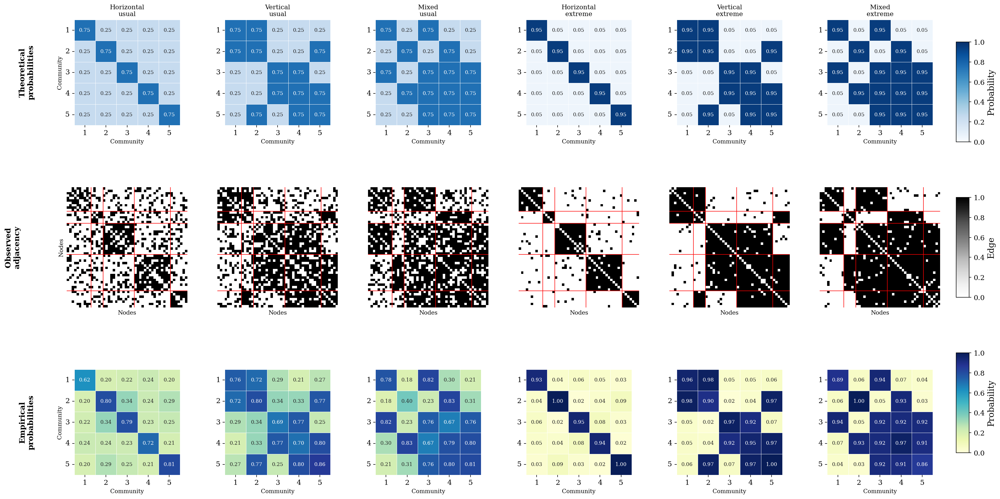

In [38]:
fig, axes = plt.subplots(3, 6,figsize=(23, 12),gridspec_kw={"height_ratios": [1, 1.5, 1]})
scenarios = list(scenario_config.keys())
for j, name in enumerate(scenarios):
    P = probability_matrices[name]
    Y = adjacency_matrices[name]
    P_hat = observed_probability_matrices[name]
    sns.heatmap(P,ax=axes[0, j],cmap="Blues",vmin=0,vmax=1,annot=True,fmt=".2f",square=True,cbar=False,linewidths=0.4,annot_kws={"size": 8})
    axes[0, j].set_title(name.replace("_", "\n"),fontsize=10)
    axes[0, j].set_xlabel("Community", fontsize=9)
    axes[0, j].set_ylabel("Community" if j == 0 else "", fontsize=9)
    axes[0, j].set_xticklabels(range(1, K+1))
    axes[0, j].set_yticklabels(range(1, K+1),rotation=0)
    sns.heatmap(Y,ax=axes[1, j],cmap="Greys",vmin=0,vmax=1,square=True,cbar=False,xticklabels=False,yticklabels=False)
    axes[1, j].set_xlabel("Nodes", fontsize=9)
    axes[1, j].set_ylabel("Nodes" if j == 0 else "", fontsize=9)
    boundaries = np.cumsum(sizes)
    for boundary in boundaries[:-1]:
        axes[1, j].axhline(boundary,color="red",linewidth=0.8)
        axes[1, j].axvline(boundary,color="red",linewidth=0.8)
    sns.heatmap(P_hat,ax=axes[2, j],cmap="YlGnBu",vmin=0,vmax=1,annot=True,fmt=".2f",square=True,cbar=False,linewidths=0.4,annot_kws={"size": 8})
    axes[2, j].set_xlabel("Community", fontsize=9)
    axes[2, j].set_ylabel("Community" if j == 0 else "", fontsize=9)
    axes[2, j].set_xticklabels(range(1, K+1))
    axes[2, j].set_yticklabels(range(1, K+1),rotation=0)
row_labels = ["Theoretical\nprobabilities","Observed\nadjacency","Empirical\nprobabilities"]
for i, label in enumerate(row_labels):
    axes[i, 0].annotate(label,xy=(-0.45, 0.5),xycoords="axes fraction",rotation=90,ha="center",va="center",fontsize=12,fontweight="bold")
fig.subplots_adjust(left=0.10,right=0.92,top=0.90,bottom=0.08,wspace=0.25,hspace=0.35)
cbar_ax1 = fig.add_axes([0.935, 0.68, 0.012, 0.18])
sm1 = plt.cm.ScalarMappable(cmap="Blues",norm=plt.Normalize(0, 1))
fig.colorbar(sm1,cax=cbar_ax1,label="Probability")
cbar_ax2 = fig.add_axes([0.935, 0.40, 0.012, 0.18])
sm2 = plt.cm.ScalarMappable(cmap="Greys",norm=plt.Normalize(0, 1))
fig.colorbar(sm2,cax=cbar_ax2,label="Edge")
cbar_ax3 = fig.add_axes([0.935, 0.12, 0.012, 0.18])
sm3 = plt.cm.ScalarMappable(cmap="YlGnBu",norm=plt.Normalize(0, 1))
fig.colorbar(sm3,cax=cbar_ax3,label="Probability")
plt.savefig("SBM_all_scenarios_3x6.pdf",format="pdf",bbox_inches="tight")
plt.show()

## Prior ellictation

In [40]:

from scipy.optimize import brentq
from scipy.special import gammaln
from scipy.stats import poisson

def rising_log(a, n):
    return gammaln(a + n) - gammaln(a)
def expected_K_DP(n, alpha):
    i = np.arange(n)
    return np.sum(alpha / (alpha + i))
def calibrate_DP(n, K_target):
    return brentq(lambda alpha: expected_K_DP(n, alpha) - K_target,1e-8,1e6)
def expected_K_PY(n, alpha, sigma):
    i = np.arange(n)
    return np.sum((alpha + sigma * i) / (alpha + i))
def calibrate_PY(n, K_target, sigma=0.1):
    lower = -sigma + 1e-8
    K_min = expected_K_PY(n, lower, sigma)
    K_max = expected_K_PY(n, 1e6, sigma)
    if not (K_min <= K_target <= K_max):
        raise ValueError(f"PY: Not possible with sigma={sigma}. "
            f"Approximate range of E[K] is [{K_min:.4f}, {K_max:.4f}].")
    return brentq(lambda alpha: expected_K_PY(n, alpha, sigma) - K_target,lower,1e6)
def expected_K_DM(n, beta, H):
    log_p_empty = rising_log((H - 1) * beta, n)- rising_log(H * beta, n)
    return H * (1 - np.exp(log_p_empty))
def calibrate_DM(n, K_target, H):
    return brentq(lambda beta: expected_K_DM(n, beta, H) - K_target,1e-8,1e5)
def expected_K_MFM(n, rho, p_k):
    p_k = np.asarray(p_k, dtype=float)
    p_k = p_k / p_k.sum()
    M_values = np.arange(1, len(p_k) + 1)
    expected = 0.0
    for M, pM in zip(M_values, p_k):
        if pM == 0:
            continue
        log_p_empty = rising_log((M - 1) * rho, n)- rising_log(M * rho, n)
        expected_conditional = M * (1 - np.exp(log_p_empty))
        expected += pM * expected_conditional
    return expected
def calibrate_MFM(n, K_target, p_k):
    max_K = len(p_k)
    return brentq(lambda rho: expected_K_MFM(n, rho, p_k) - K_target,1e-8,1e5)
def expected_K_PCPP(n, theta, omega, tol=1e-10):
    M_max = int(poisson.ppf(1 - tol, theta)) + 1
    M_values = np.arange(1, M_max + 1)
    probabilities = poisson.pmf(M_values - 1, theta)
    probabilities /= probabilities.sum()
    expected = 0.0
    for M, pM in zip(M_values, probabilities):
        if M == 1:
            expected_conditional = 1.0
            expected += pM * expected_conditional
            continue
        if omega == 0:
            log_p_empty = n * np.log((M - 1) / M)
        else:
            alpha_M = M / (omega**2) - 1 / M
            log_p_empty = rising_log((M - 1) * alpha_M, n) - rising_log(M * alpha_M, n)
        expected_conditional = M * (1 - np.exp(log_p_empty))
        expected += pM * expected_conditional
    return expected
def calibrate_PCPP(n, K_target, omega=0.0, tol=1e-10):
    def objective(theta):
        return expected_K_PCPP(n, theta, omega, tol) - K_target
    return brentq(objective, 1e-8, 1e4)
def simulate_GN_partition(n, gamma, seed=None):
    rng = np.random.default_rng(seed)
    prior = bdn.PartitionPrior(bdn.PriorType.GN,gamma)
    labels = [0]
    for i in range(1, n):
        current = bdn.Partition(labels)
        K = len(set(labels))
        candidates = []
        for k in range(K):
            new_labels = labels.copy()
            old_label = sorted(set(labels))[k]
            new_labels.append(old_label)
            candidates.append(new_labels)
        new_labels = labels.copy()
        new_labels.append(max(labels) + 1)
        candidates.append(new_labels)
        log_probs = np.array([prior.log_probability(bdn.Partition(candidate)) for candidate in candidates])
        log_probs -= np.max(log_probs)
        probs = np.exp(log_probs)
        probs /= probs.sum()
        chosen = rng.choice(len(candidates), p=probs)
        labels = candidates[chosen]
    return len(set(labels))
def expected_K_GN_MC(n, gamma, simulations=200, seed=123):
    values = [simulate_GN_partition(n,gamma,seed=seed + s) for s in range(simulations)]
    return np.mean(values)
def calibrate_GN_MC(n, K_target, simulations=200, seed=123):
    gamma_grid = np.linspace(0.1, 0.9, 11)
    results = []
    for gamma in gamma_grid:
        K_est = expected_K_GN_MC(n,gamma,simulations=simulations,seed=seed)
        results.append((gamma, K_est))
    best_gamma, best_K = min(results,key=lambda x: abs(x[1] - K_target))
    return best_gamma, best_K, results

In [42]:
K_target = 5
n = 50
alpha_DP = calibrate_DP(n, K_target)
sigma_PY = 0.01
alpha_PY = calibrate_PY(n,K_target,sigma=sigma_PY)
H_DM = 30
beta_DM = calibrate_DM(n,K_target,H=H_DM)
p_k_MFM = np.ones(30) / 30
rho_MFM = calibrate_MFM(n,K_target,p_k=p_k_MFM)
gamma_GN, K_GN_est, GN_results = calibrate_GN_MC(n,K_target,simulations=100)
omega_PCPP = 0.5
theta_PCPP = calibrate_PCPP(n,K_target,omega=omega_PCPP)
print("Objective E[K] =", K_target)
print("\nDP")
print("alpha =", alpha_DP)
print("E[K] =", expected_K_DP(n, alpha_DP))
print("\nPY")
print("alpha =", alpha_PY)
print("sigma =", sigma_PY)
print("E[K] =", expected_K_PY(n, alpha_PY, sigma_PY))
print("\nDM")
print("beta =", beta_DM)
print("H =", H_DM)
print("E[K] =", expected_K_DM(n, beta_DM, H_DM))
print("\nMFM")
print("rho =", rho_MFM)
print("E[K] =", expected_K_MFM(n, rho_MFM, p_k_MFM))
print("\nGN")
print("gamma =", gamma_GN)
print("E[K] estimated by simulation =", K_GN_est)
print("\nPCPP")
print("theta =", theta_PCPP)
print("omega =", omega_PCPP)
print("E[K] =", expected_K_PCPP(n, theta_PCPP, omega_PCPP))

Objective E[K] = 5

DP
alpha = 1.1787275669831943
E[K] = 5.0

PY
alpha = 1.0161300150172323
sigma = 0.01
E[K] = 5.000000000000001

DM
beta = 0.04473669476337631
H = 30
E[K] = 4.999999999999563

MFM
rho = 0.1076381362769065
E[K] = 4.99999999999996

GN
gamma = 0.66
E[K] estimated by simulation = 5.45

PCPP
theta = 4.0058560574681445
omega = 0.5
E[K] = 5.000000000000011


## Load results

In [3]:
with open("SBM_simulation_36_runs.pkl", "rb") as f:
    all_results = pickle.load(f)
successful_runs = {name: result for name, result in all_results.items() if result["status"] == "success"}
print("Succesful executions:", len(successful_runs))

Succesful executions: 36


In [4]:
for name, result in list(all_results.items())[:2]:
    print("\nExecution:", name)
    for key, value in result.items():
        if isinstance(value, np.ndarray):
            print(key, "| shape:", value.shape, "| dtype:", value.dtype)
        else:
            print(key, "|", type(value))


Execution: Horizontal_usual_DP
scenario | <class 'str'>
prior | <class 'str'>
prior_parameters | <class 'dict'>
n | <class 'int'>
m | <class 'int'>
density | <class 'float'>
K_true | <class 'int'>
z_true | shape: (50,) | dtype: int64
P | shape: (5, 5) | dtype: float64
sizes | <class 'list'>
adjacency | shape: (50, 50) | dtype: int64
final_partition | shape: (50,) | dtype: int64
K_final | <class 'int'>
samples | shape: (1000, 50) | dtype: int64
K_trace | shape: (1000,) | dtype: int64
log_posterior | shape: (100000,) | dtype: float64
saved_samples | <class 'int'>
gibbs_iterations | <class 'int'>
split_merge_iterations | <class 'int'>
gibbs_probability | <class 'float'>
split_attempts | <class 'int'>
merge_attempts | <class 'int'>
accepted_splits | <class 'int'>
accepted_merges | <class 'int'>
split_acceptance_rate | <class 'float'>
merge_acceptance_rate | <class 'float'>
ESS_K | <class 'float'>
ESS_log_posterior | <class 'float'>
burn_in | <class 'int'>
thinning | <class 'int'>
seed | <

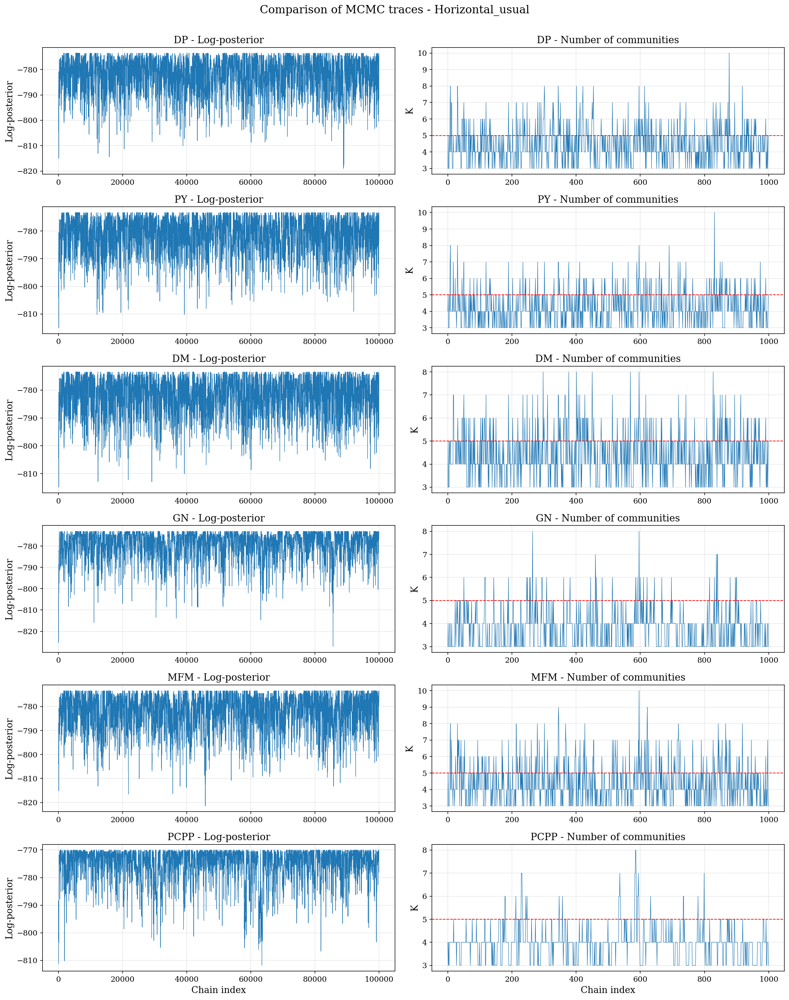

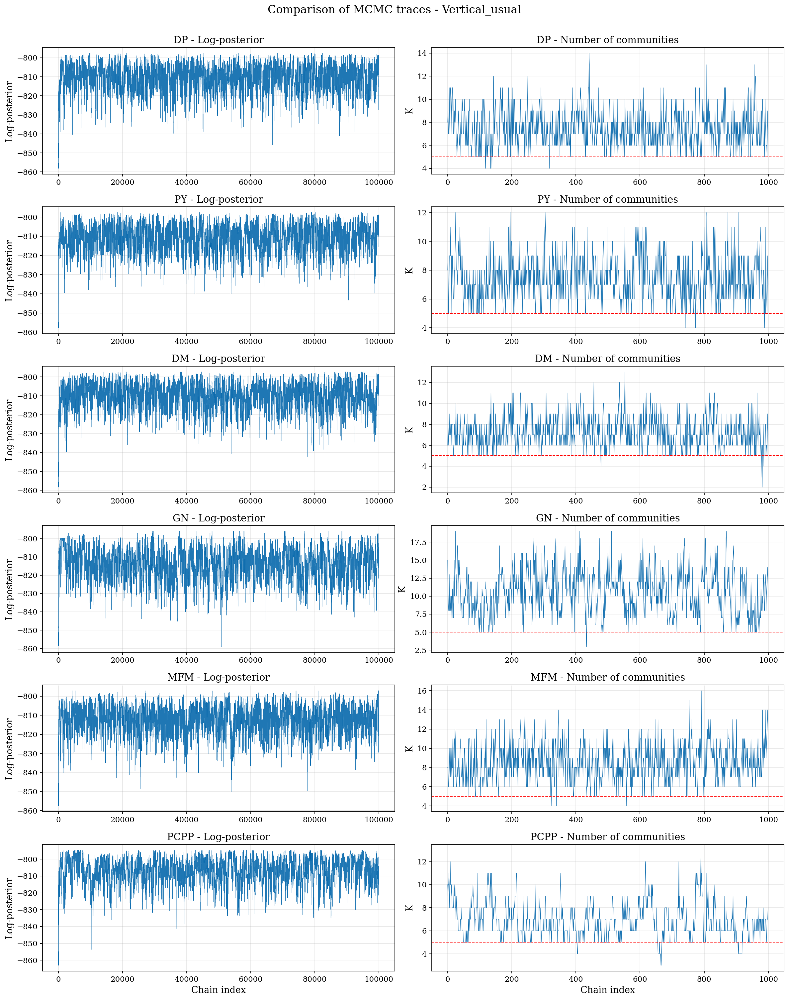

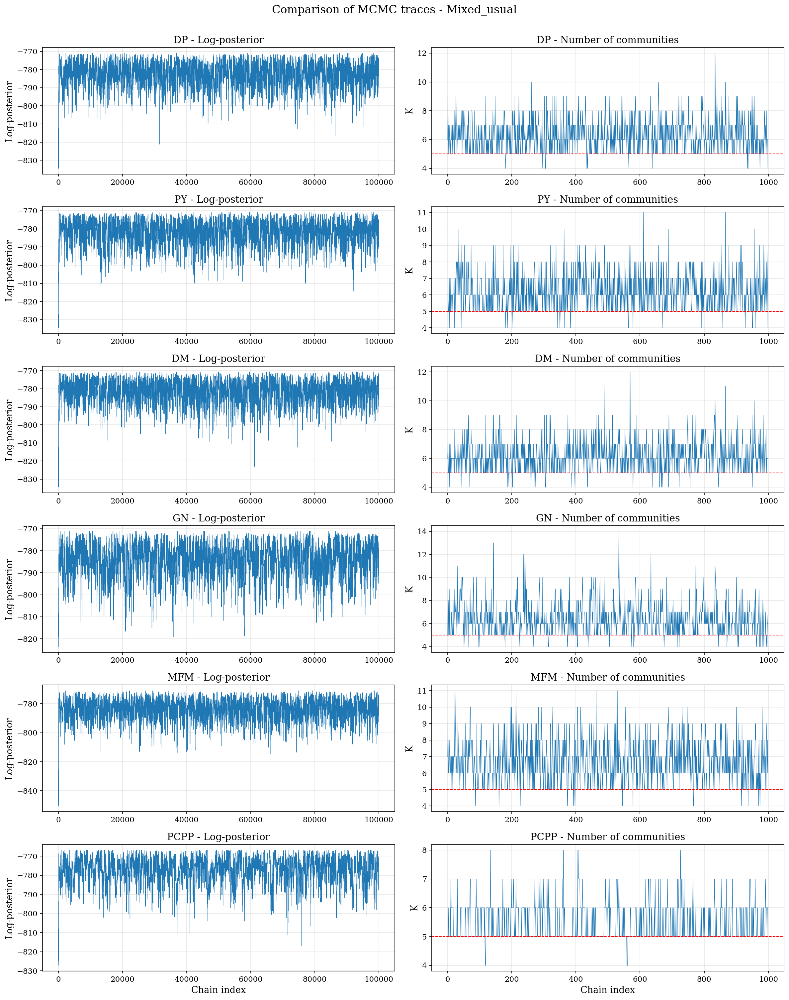

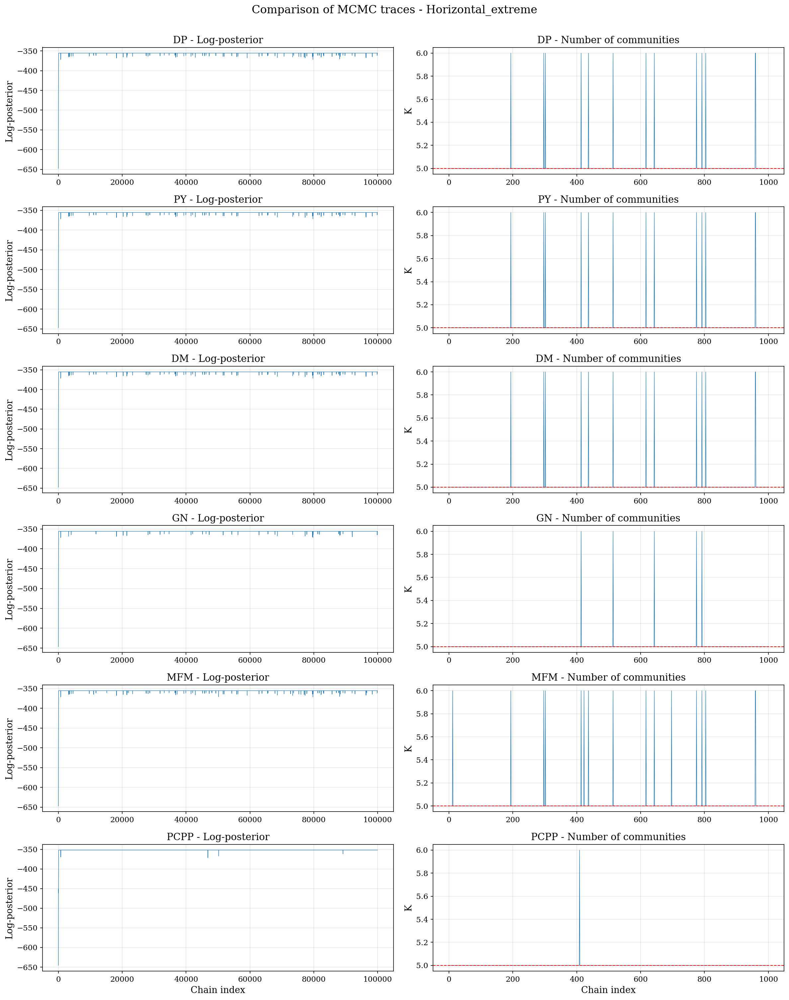

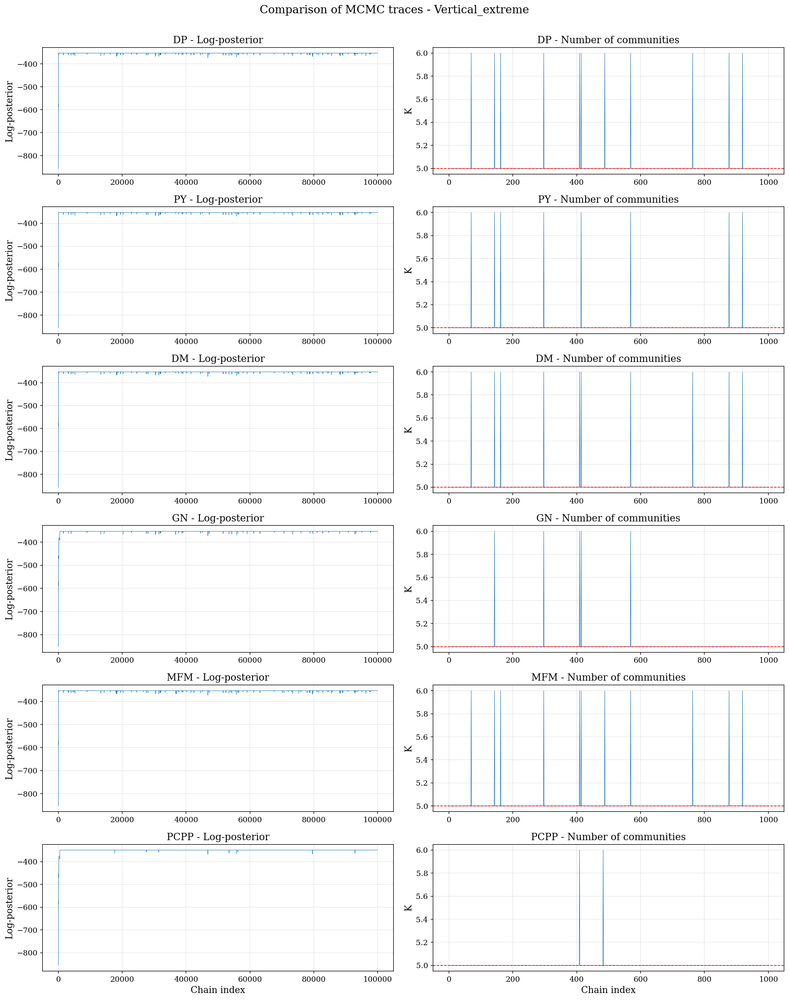

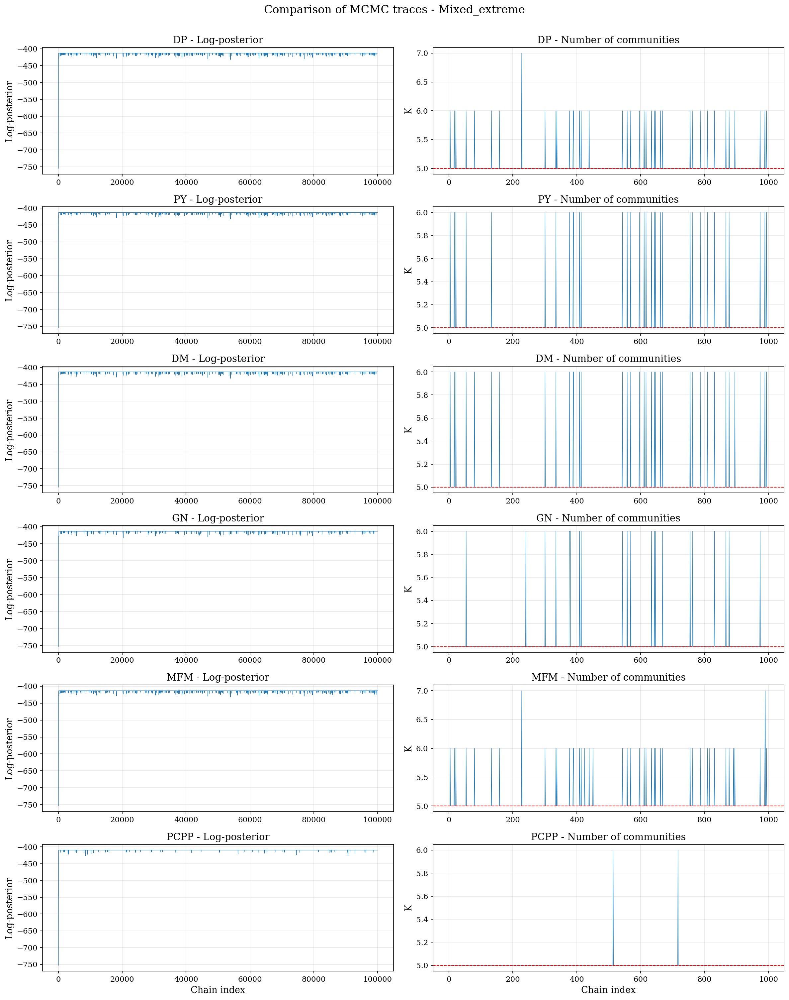

In [5]:
def plot_mcmc_traces(run_name, all_results):
    result = all_results[run_name]
    log_post = np.asarray(result["log_posterior"])
    k_trace = np.asarray(result["K_trace"])
    fig, axes = plt.subplots(2, 1,figsize=(14, 8),sharex=False)
    axes[0].plot(np.arange(len(log_post)),log_post,linewidth=0.7)
    axes[0].set_title(f"Log-posterior trace - {run_name}")
    axes[0].set_ylabel("Log-posterior")
    axes[0].set_xlabel("Iteration")
    axes[0].grid(alpha=0.3)
    axes[1].plot(np.arange(len(k_trace)),k_trace,linewidth=0.7)
    axes[1].axhline(y=result["K_true"],color="red",linestyle="--",label=f"K verdadero = {result['K_true']}")
    axes[1].set_title(f"Number of communities trace - {run_name}")
    axes[1].set_ylabel("Number of communities (K)")
    axes[1].set_xlabel("Iteration")
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
def compare_priors_traces(scenario, all_results):
    prior_names = ["DP", "PY", "DM", "GN", "MFM", "PCPP"]
    fig, axes = plt.subplots(6, 2,figsize=(16, 20))
    for i, prior_name in enumerate(prior_names):
        run_name = f"{scenario}_{prior_name}"
        if run_name not in all_results:
            continue
        result = all_results[run_name]
        log_post = np.asarray(result["log_posterior"])
        k_trace = np.asarray(result["K_trace"])
        axes[i, 0].plot(log_post,linewidth=0.6)
        axes[i, 0].set_title(f"{prior_name} - Log-posterior")
        axes[i, 0].set_ylabel("Log-posterior")
        axes[i, 0].grid(alpha=0.3)
        axes[i, 1].plot(k_trace,linewidth=0.6)
        axes[i, 1].axhline(result["K_true"],color="red",linestyle="--",linewidth=1)
        axes[i, 1].set_title(f"{prior_name} - Number of communities")
        axes[i, 1].set_ylabel("K")
        axes[i, 1].grid(alpha=0.3)
    axes[-1, 0].set_xlabel("Chain index")
    axes[-1, 1].set_xlabel("Chain index")
    fig.suptitle(f"Comparison of MCMC traces - {scenario}",fontsize=16,y=1.002)
    plt.tight_layout()
    plt.show()
scenarios = ["Horizontal_usual","Vertical_usual","Mixed_usual","Horizontal_extreme","Vertical_extreme","Mixed_extreme"]
for scenario in scenarios:
    compare_priors_traces(scenario, successful_runs)

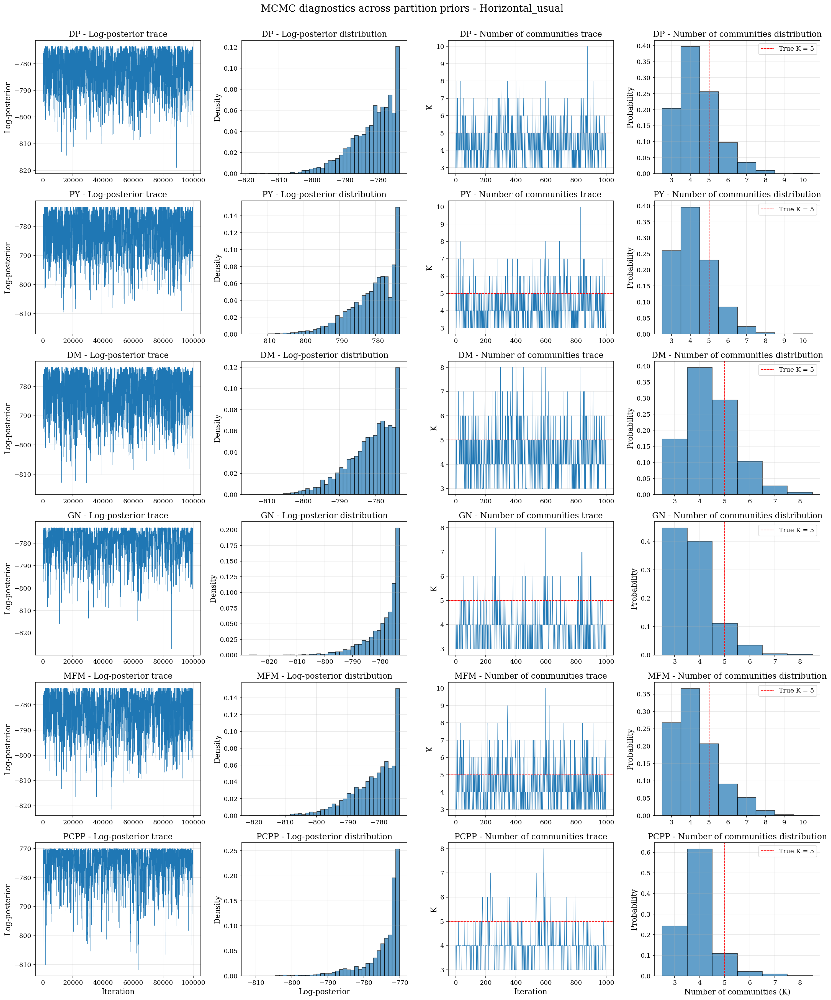

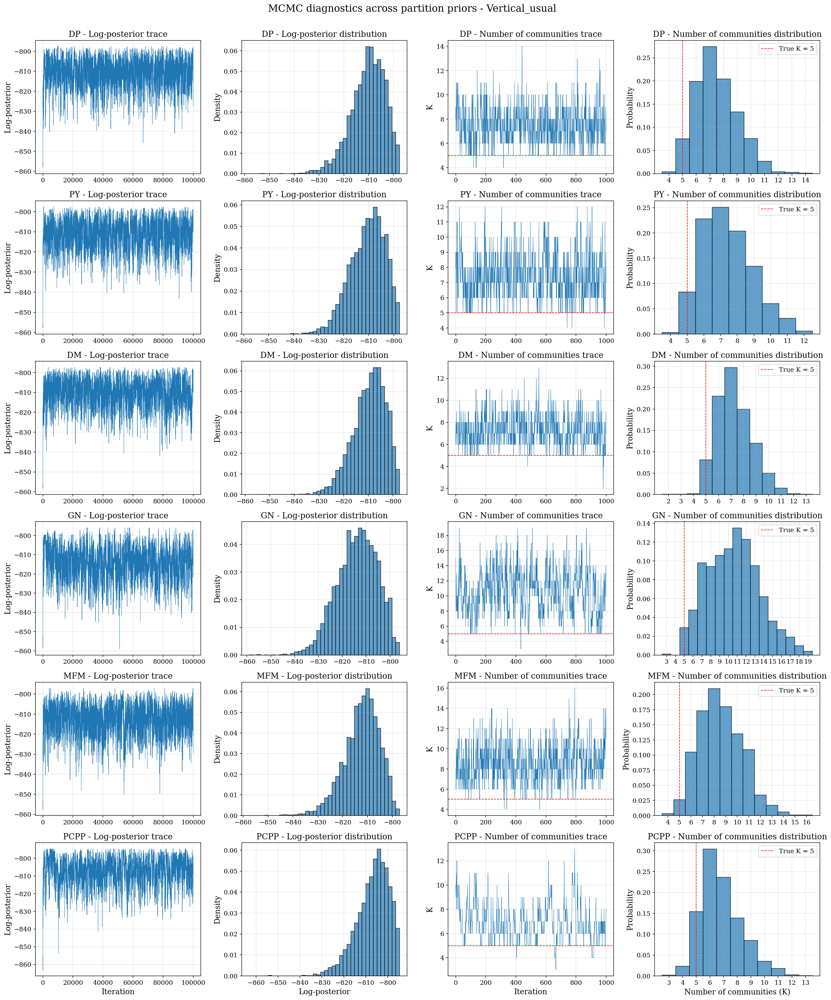

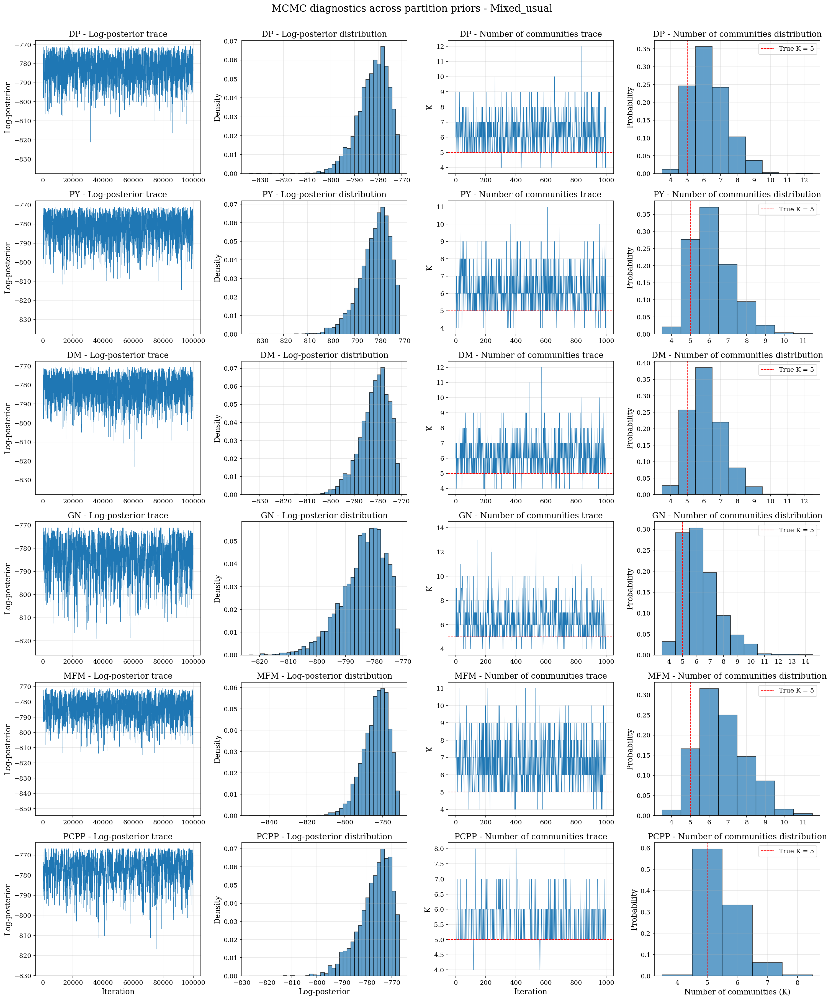

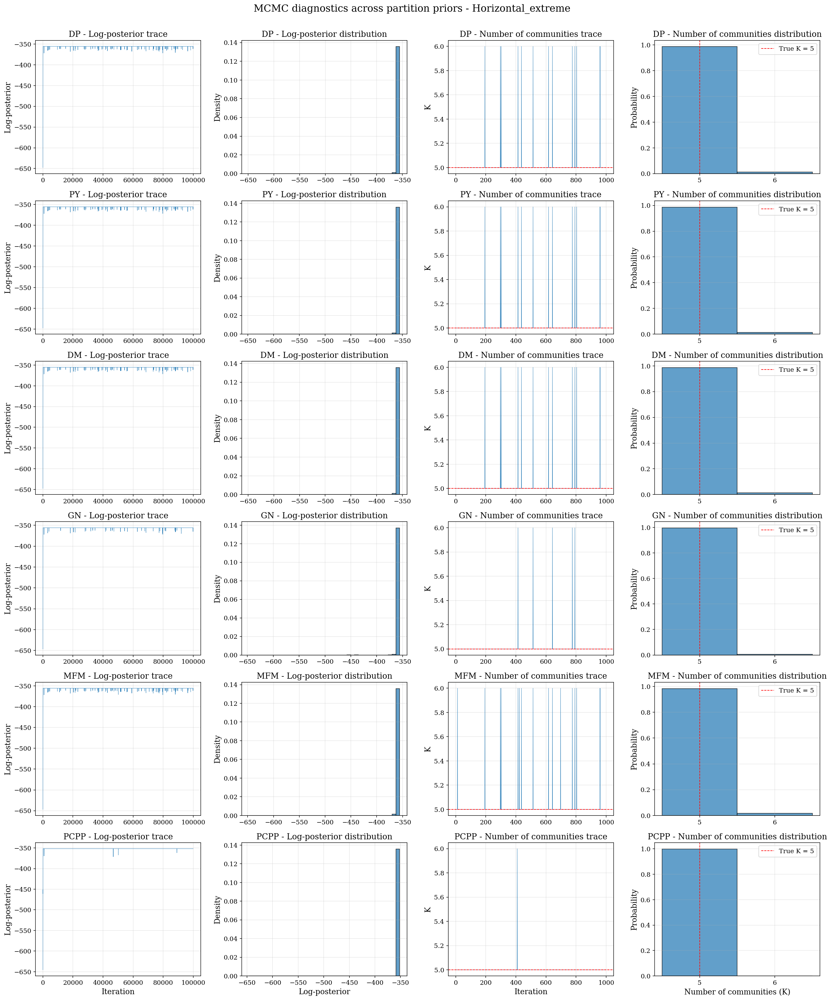

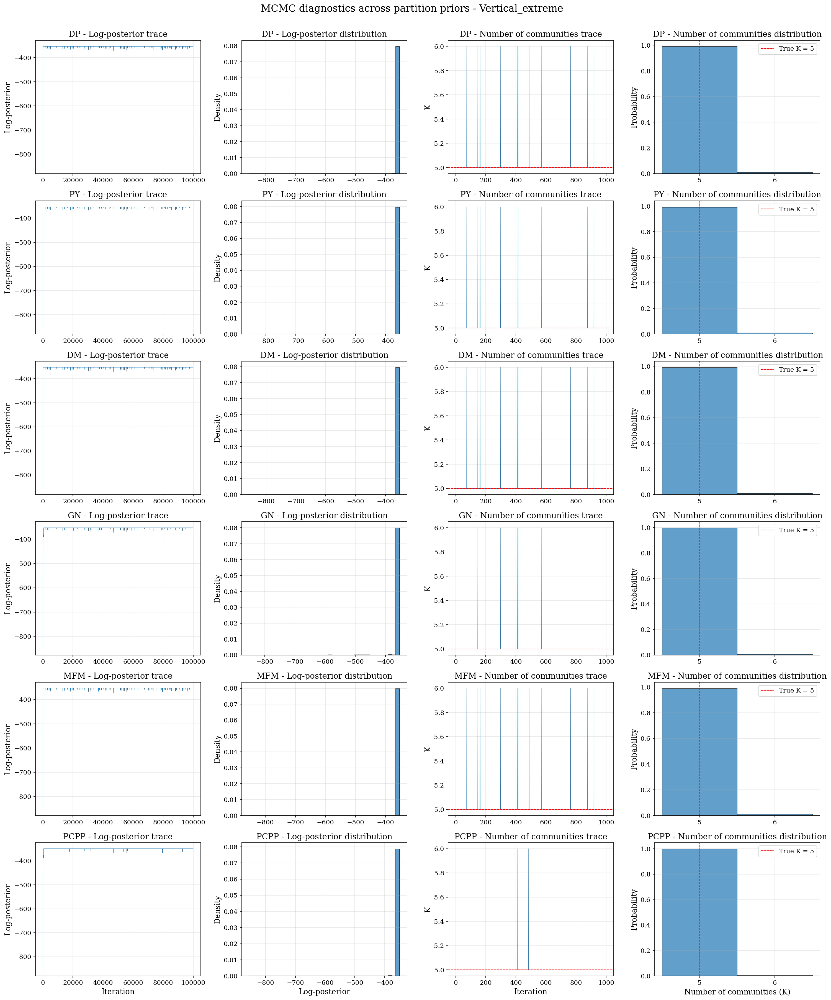

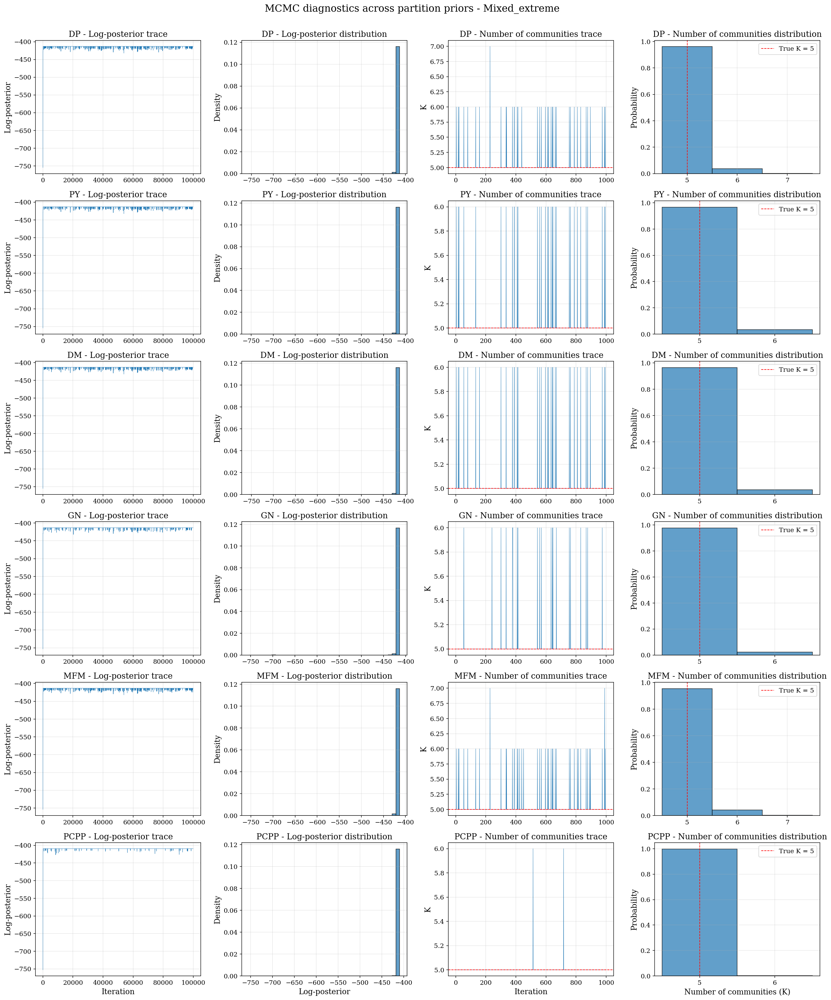

In [ ]:
def plot_mcmc_diagnostics(run_name, all_results):
    result = all_results[run_name]
    log_post = np.asarray(result["log_posterior"])
    k_trace = np.asarray(result["K_trace"])
    k_true = result.get("K_true", None)
    fig, axes = plt.subplots(2, 2,figsize=(14, 9))
    axes[0, 0].plot(log_post,linewidth=0.6,alpha=0.8)
    axes[0, 0].set_title("Log-posterior trace")
    axes[0, 0].set_xlabel("Iteration")
    axes[0, 0].set_ylabel("Log-posterior")
    axes[0, 0].grid(alpha=0.3)
    axes[0, 1].hist(log_post,bins=40,density=True,alpha=0.7,edgecolor="black")
    axes[0, 1].set_title("Log-posterior distribution")
    axes[0, 1].set_xlabel("Log-posterior")
    axes[0, 1].set_ylabel("Density")
    axes[0, 1].grid(alpha=0.3)
    axes[1, 0].plot(k_trace,linewidth=0.6,alpha=0.8)
    if k_true is not None:
        axes[1, 0].axhline(y=k_true,color="red",linestyle="--",label=f"True number of communities = {k_true}")
        axes[1, 0].legend()
    axes[1, 0].set_title("Number of communities trace")
    axes[1, 0].set_xlabel("Iteration")
    axes[1, 0].set_ylabel("Number of communities (K)")
    axes[1, 0].grid(alpha=0.3)
    k_min = int(np.min(k_trace))
    k_max = int(np.max(k_trace))
    bins = np.arange(k_min - 0.5, k_max + 1.5, 1)
    axes[1, 1].hist(k_trace,bins=bins,density=True,alpha=0.7,edgecolor="black")
    if k_true is not None:
        axes[1, 1].axvline(x=k_true,color="red",linestyle="--",label=f"True K = {k_true}")
        axes[1, 1].legend()
    axes[1, 1].set_title("Number of communities distribution")
    axes[1, 1].set_xlabel("Number of communities (K)")
    axes[1, 1].set_ylabel("Probability")
    axes[1, 1].set_xticks(range(k_min, k_max + 1))
    axes[1, 1].grid(alpha=0.3)
    fig.suptitle(f"MCMC diagnostics - {run_name}",fontsize=15)
    plt.tight_layout()
    plt.savefig(f"MCMC_diagnostics_{run_name}.pdf",bbox_inches="tight")
    plt.show()
def compare_priors_diagnostics(scenario, all_results):
    prior_names = ["DP", "PY", "DM", "GN", "MFM", "PCPP"]
    fig, axes = plt.subplots(
        6, 4,
        figsize=(20, 24)
    )

    for i, prior_name in enumerate(prior_names):

        run_name = f"{scenario}_{prior_name}"

        if run_name not in all_results:
            continue

        result = all_results[run_name]

        if result["status"] != "success":
            continue

        log_post = np.asarray(result["log_posterior"])
        k_trace = np.asarray(result["K_trace"])

        k_true = result.get("K_true", None)

        # -------------------------------------
        # 1. Log-posterior trace
        # -------------------------------------

        axes[i, 0].plot(
            log_post,
            linewidth=0.5
        )

        axes[i, 0].set_title(
            f"{prior_name} - Log-posterior trace"
        )

        axes[i, 0].set_ylabel("Log-posterior")
        axes[i, 0].grid(alpha=0.3)

        # -------------------------------------
        # 2. Log-posterior histogram
        # -------------------------------------

        axes[i, 1].hist(
            log_post,
            bins=40,
            density=True,
            alpha=0.7,
            edgecolor="black"
        )

        axes[i, 1].set_title(
            f"{prior_name} - Log-posterior distribution"
        )

        axes[i, 1].set_ylabel("Density")
        axes[i, 1].grid(alpha=0.3)

        # -------------------------------------
        # 3. Number of communities trace
        # -------------------------------------

        axes[i, 2].plot(
            k_trace,
            linewidth=0.5
        )

        if k_true is not None:
            axes[i, 2].axhline(
                k_true,
                color="red",
                linestyle="--",
                linewidth=1
            )

        axes[i, 2].set_title(
            f"{prior_name} - Number of communities trace"
        )

        axes[i, 2].set_ylabel("K")
        axes[i, 2].grid(alpha=0.3)

        # -------------------------------------
        # 4. Number of communities histogram
        # -------------------------------------

        k_min = int(np.min(k_trace))
        k_max = int(np.max(k_trace))

        bins = np.arange(
            k_min - 0.5,
            k_max + 1.5,
            1
        )

        axes[i, 3].hist(
            k_trace,
            bins=bins,
            density=True,
            alpha=0.7,
            edgecolor="black"
        )

        if k_true is not None:
            axes[i, 3].axvline(
                k_true,
                color="red",
                linestyle="--",
                linewidth=1,
                label=f"True K = {k_true}"
            )
            axes[i, 3].legend()

        axes[i, 3].set_title(
            f"{prior_name} - Number of communities distribution"
        )

        axes[i, 3].set_ylabel("Probability")
        axes[i, 3].set_xticks(
            range(k_min, k_max + 1)
        )
        axes[i, 3].grid(alpha=0.3)

    # -----------------------------------------
    # Global labels and layout
    # -----------------------------------------

    axes[-1, 0].set_xlabel("Iteration")
    axes[-1, 1].set_xlabel("Log-posterior")
    axes[-1, 2].set_xlabel("Iteration")
    axes[-1, 3].set_xlabel("Number of communities (K)")

    fig.suptitle(
        f"MCMC diagnostics across partition priors - {scenario}",
        fontsize=17,
        y=1.002
    )

    plt.tight_layout()



    plt.show()


scenarios = [
    "Horizontal_usual",
    "Vertical_usual",
    "Mixed_usual",
    "Horizontal_extreme",
    "Vertical_extreme",
    "Mixed_extreme"
]

for scenario in scenarios:

    compare_priors_diagnostics(
        scenario,
        successful_runs
    )

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

def variation_of_information(labels_true, labels_pred):

    labels_true = np.asarray(labels_true)
    labels_pred = np.asarray(labels_pred)

    n = len(labels_true)

    contingency = np.zeros((
        len(np.unique(labels_true)),
        len(np.unique(labels_pred))
    ))

    true_labels, true_inverse = np.unique(
        labels_true, return_inverse=True
    )

    pred_labels, pred_inverse = np.unique(
        labels_pred, return_inverse=True
    )

    np.add.at(
        contingency,
        (true_inverse, pred_inverse),
        1
    )

    probabilities = contingency / n

    p_true = probabilities.sum(axis=1)
    p_pred = probabilities.sum(axis=0)

    entropy_true = -np.sum(
        p_true[p_true > 0] * np.log(p_true[p_true > 0])
    )

    entropy_pred = -np.sum(
        p_pred[p_pred > 0] * np.log(p_pred[p_pred > 0])
    )

    mutual_information = 0.0

    for i in range(probabilities.shape[0]):
        for j in range(probabilities.shape[1]):

            pij = probabilities[i, j]

            if pij > 0:
                mutual_information += pij * np.log(
                    pij / (p_true[i] * p_pred[j])
                )

    return entropy_true + entropy_pred - 2 * mutual_information

def calculate_partition_metrics(all_results):

    metrics_results = {}

    for run_name, result in all_results.items():

        if result["status"] != "success":
            continue

        z_true = np.asarray(result["z_true"])
        samples = np.asarray(result["samples"])

        vi_values = []
        ari_values = []
        nmi_values = []

        for sample in samples:

            vi = variation_of_information(
                z_true,
                sample
            )

            ari = adjusted_rand_score(
                z_true,
                sample
            )

            nmi = normalized_mutual_info_score(
                z_true,
                sample
            )

            vi_values.append(vi)
            ari_values.append(ari)
            nmi_values.append(nmi)

        metrics_results[run_name] = {
            "scenario": result["scenario"],
            "prior": result["prior"],
            "VI": np.array(vi_values),
            "ARI": np.array(ari_values),
            "NMI": np.array(nmi_values)
        }

    return metrics_results

In [14]:
partition_metrics = calculate_partition_metrics(
    successful_runs
)

print("Number of analyzed executions:", len(partition_metrics))

Number of analyzed executions: 36


In [ ]:
def plot_partition_metrics(run_name, partition_metrics):

    result = partition_metrics[run_name]

    metrics = ["VI", "ARI", "NMI"]

    fig, axes = plt.subplots(
        3, 2,
        figsize=(14, 12)
    )

    for i, metric in enumerate(metrics):

        values = result[metric]

        # Trace plot
        axes[i, 0].plot(
            values,
            linewidth=0.8,
            alpha=0.8
        )

        axes[i, 0].set_title(
            f"{metric} - Posterior trace"
        )

        axes[i, 0].set_xlabel("Posterior sample")
        axes[i, 0].set_ylabel(metric)
        axes[i, 0].grid(alpha=0.3)

        # Histogram
        axes[i, 1].hist(
            values,
            bins=35,
            density=True,
            alpha=0.7,
            edgecolor="black"
        )

        axes[i, 1].axvline(
            np.mean(values),
            color="red",
            linestyle="--",
            label=f"Mean = {np.mean(values):.3f}"
        )

        axes[i, 1].set_title(
            f"{metric} - Empirical distribution"
        )

        axes[i, 1].set_xlabel(metric)
        axes[i, 1].set_ylabel("Density")
        axes[i, 1].legend()
        axes[i, 1].grid(alpha=0.3)

    fig.suptitle(
        f"Partition recovery diagnostics - {run_name}",
        fontsize=15
    )

    plt.tight_layout()


    plt.show()

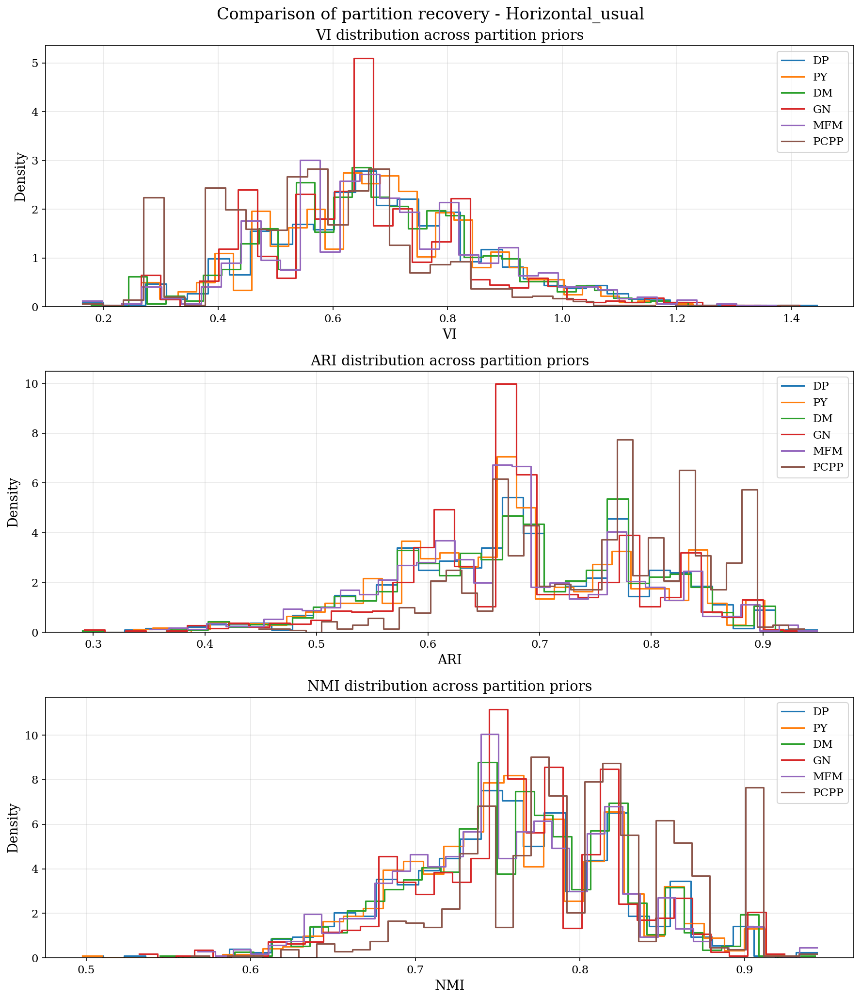

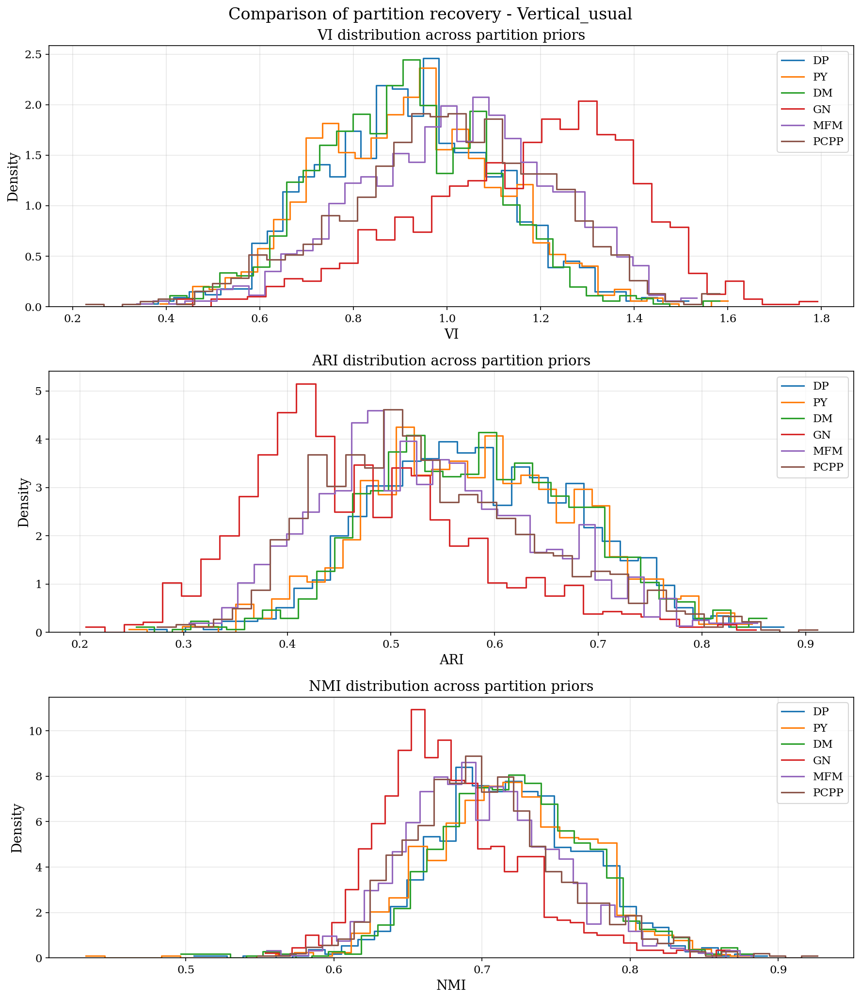

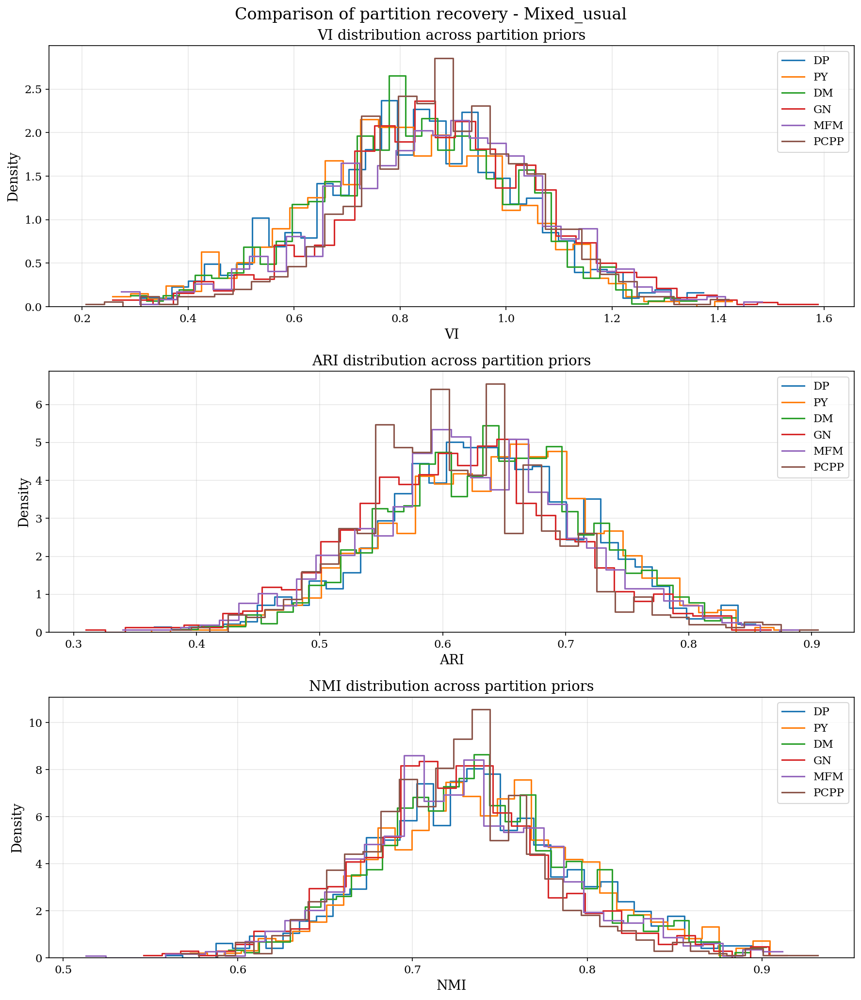

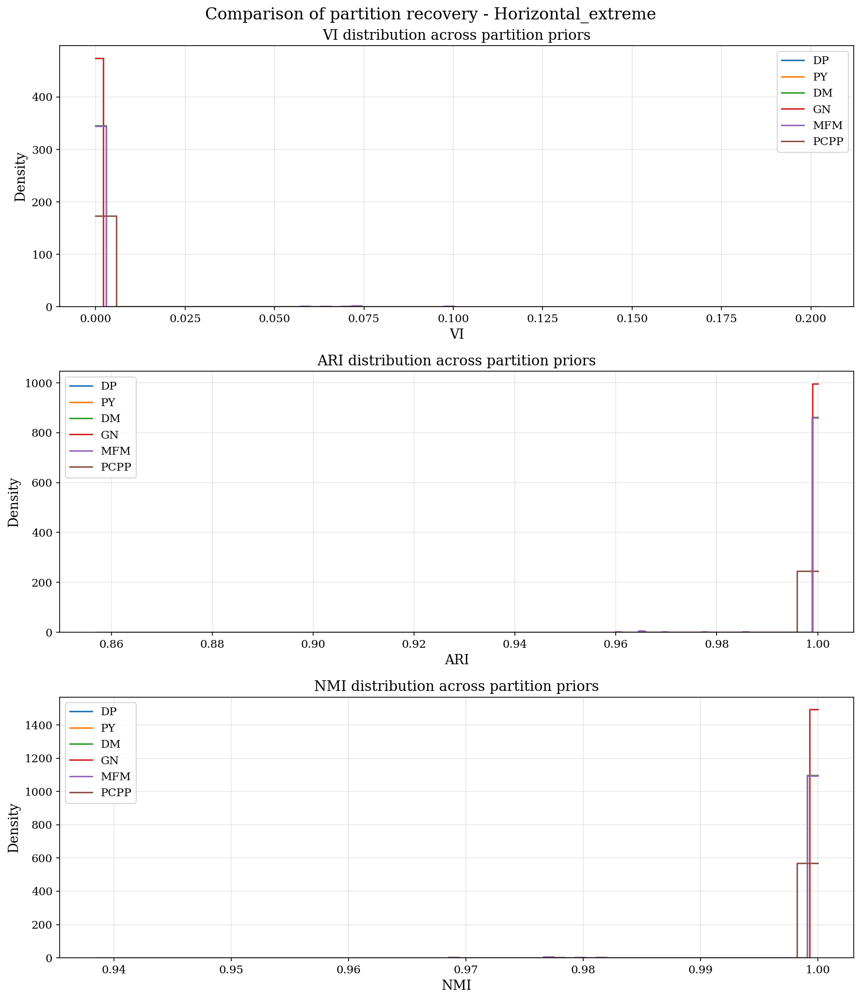

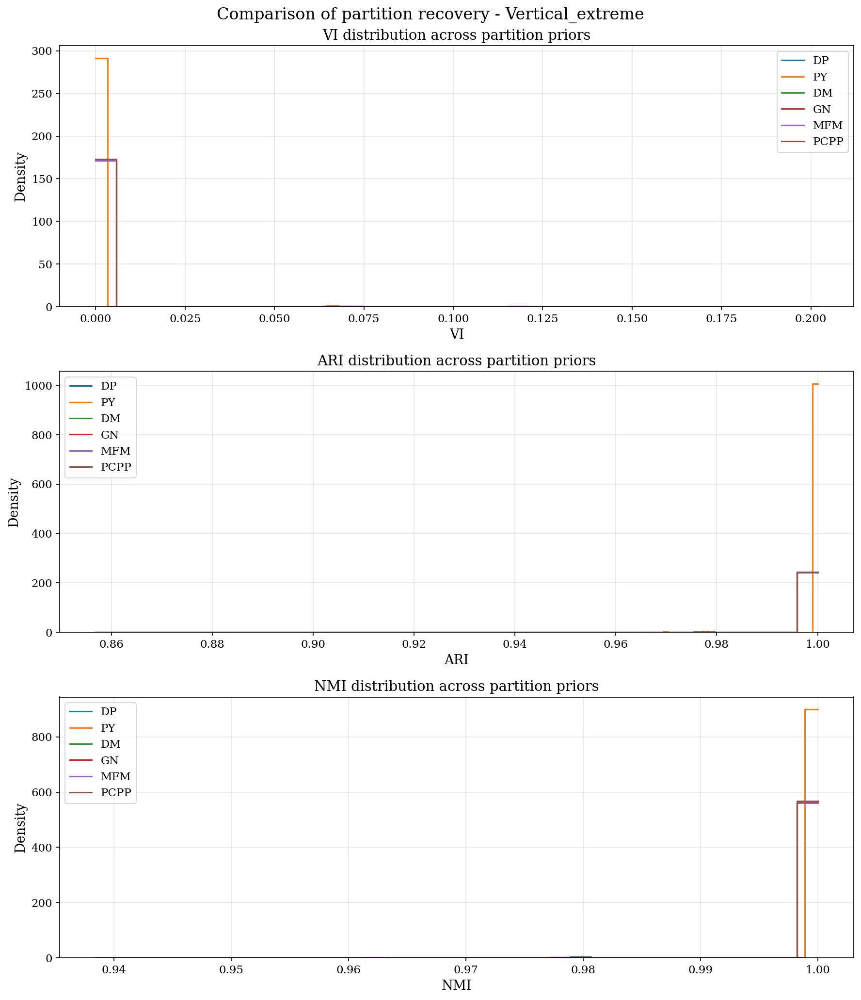

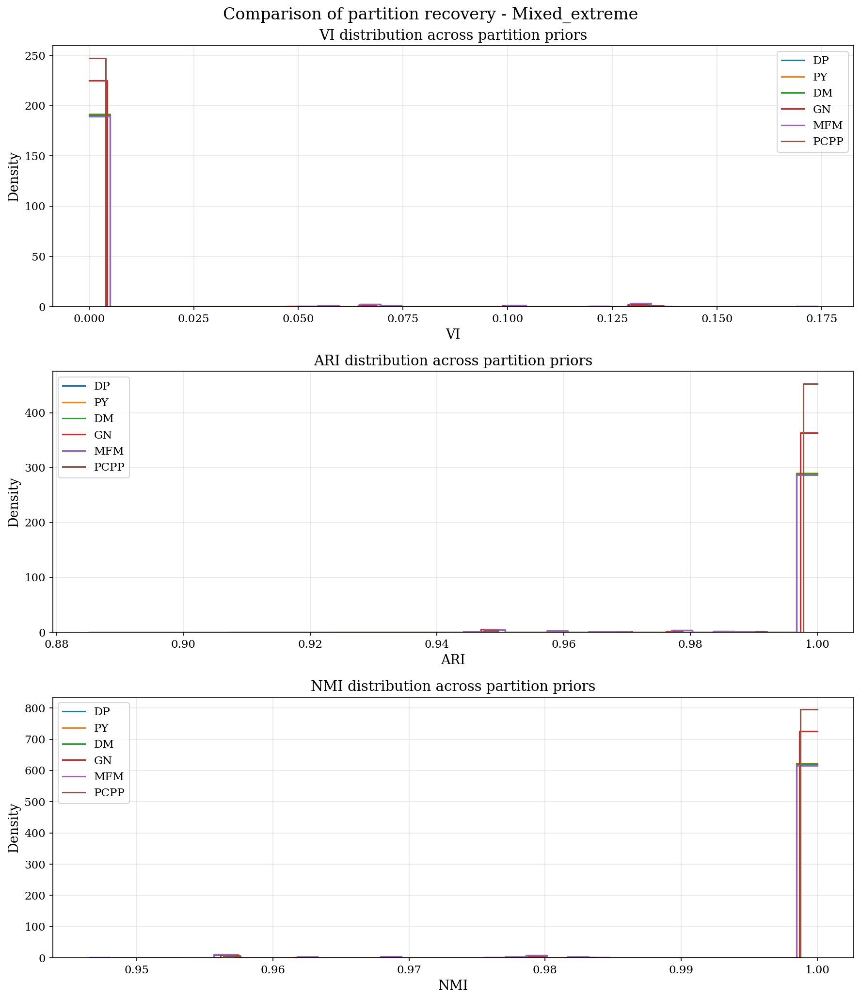

In [ ]:
def compare_priors_partition_metrics(
    scenario,
    partition_metrics
):

    prior_names = ["DP", "PY", "DM", "GN", "MFM", "PCPP"]

    metrics = ["VI", "ARI", "NMI"]

    fig, axes = plt.subplots(
        3, 1,
        figsize=(12, 14)
    )

    for i, metric in enumerate(metrics):

        for prior_name in prior_names:

            run_name = f"{scenario}_{prior_name}"

            if run_name not in partition_metrics:
                continue

            values = partition_metrics[run_name][metric]

            sns.histplot(
                values,
                bins=35,
                stat="density",
                element="step",
                fill=False,
                linewidth=1.5,
                label=prior_name,
                ax=axes[i]
            )

        axes[i].set_title(
            f"{metric} distribution across partition priors"
        )

        axes[i].set_xlabel(metric)
        axes[i].set_ylabel("Density")
        axes[i].legend()
        axes[i].grid(alpha=0.3)

    fig.suptitle(
        f"Comparison of partition recovery - {scenario}",
        fontsize=16
    )

    plt.tight_layout()

    plt.show()


scenarios = [
    "Horizontal_usual",
    "Vertical_usual",
    "Mixed_usual",
    "Horizontal_extreme",
    "Vertical_extreme",
    "Mixed_extreme"
]

for scenario in scenarios:

    compare_priors_partition_metrics(
        scenario,
        partition_metrics
    )

In [16]:
def summarize_partition_metrics(partition_metrics):

    summary = []

    for run_name, result in partition_metrics.items():

        row = {
            "scenario": result["scenario"],
            "prior": result["prior"]
        }

        for metric in ["VI", "ARI", "NMI"]:

            values = result[metric]

            row[f"{metric}_mean"] = np.mean(values)
            row[f"{metric}_sd"] = np.std(values, ddof=1)

            row[f"{metric}_q025"] = np.quantile(
                values, 0.025
            )

            row[f"{metric}_q975"] = np.quantile(
                values, 0.975
            )

        summary.append(row)

    return pd.DataFrame(summary)


metrics_summary = summarize_partition_metrics(
    partition_metrics
)

display(metrics_summary)

,scenario,prior,VI_mean,VI_sd,VI_q025,VI_q975,ARI_mean,ARI_sd,ARI_q025,ARI_q975,NMI_mean,NMI_sd,NMI_q025,NMI_q975
0,Horizontal_usual,DP,0.684139,0.187937,0.338984,1.088746,0.681158,0.110809,0.443126,0.872138,0.759786,0.064972,0.630960,0.886365
1,Horizontal_usual,PY,0.677072,0.179272,0.339032,1.052613,0.678965,0.108318,0.455133,0.872454,0.760180,0.063122,0.641575,0.884047
2,Horizontal_usual,DM,0.679308,0.179609,0.323033,1.061807,0.685598,0.107287,0.468560,0.888054,0.762459,0.062626,0.639611,0.887524
3,Horizontal_usual,GN,0.655574,0.174406,0.309003,1.036559,0.684245,0.100755,0.470312,0.892549,0.763422,0.062167,0.639160,0.896558
4,Horizontal_usual,MFM,0.689671,0.189629,0.323033,1.093910,0.673123,0.107571,0.461075,0.884547,0.757483,0.063921,0.635004,0.887524
5,Horizontal_usual,PCPP,0.570573,0.173219,0.276018,0.941837,0.753159,0.094190,0.569158,0.892549,0.800080,0.061362,0.680232,0.905359
6,Vertical_usual,DP,0.920539,0.191742,0.574908,1.294883,0.585374,0.099300,0.404233,0.776899,0.720529,0.050997,0.626524,0.820152
7,Vertical_usual,PY,0.920682,0.193686,0.562597,1.304761,0.582391,0.101120,0.394396,0.781557,0.718978,0.052283,0.622186,0.821570
8,Vertical_usual,DM,0.907636,0.185771,0.546454,1.253291,0.585001,0.099702,0.398624,0.785641,0.721568,0.052491,0.626514,0.826010
9,Vertical_usual,GN,1.168951,0.230283,0.679920,1.541895,0.471823,0.107584,0.296322,0.722796,0.678766,0.047579,0.601341,0.788218


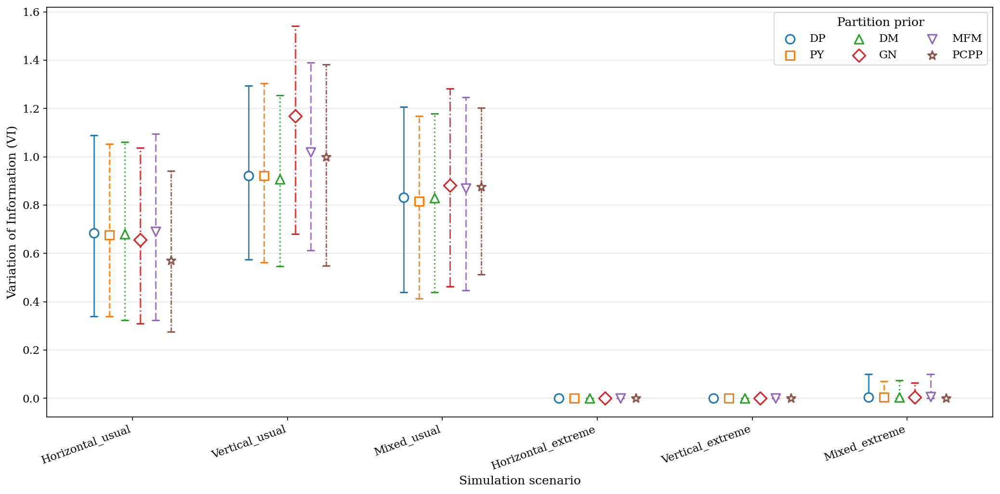

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define scenario and prior order
scenario_order = [
    "Horizontal_usual",
    "Vertical_usual",
    "Mixed_usual",
    "Horizontal_extreme",
    "Vertical_extreme",
    "Mixed_extreme"
]

prior_order = ["DP", "PY", "DM", "GN", "MFM", "PCPP"]

# Define colors for each prior
colors = {
    "DP": "#1f77b4",
    "PY": "#ff7f0e",
    "DM": "#2ca02c",
    "GN": "#d62728",
    "MFM": "#9467bd",
    "PCPP": "#8c564b"
}

# Define marker and line styles
markers = {
    "DP": "o",
    "PY": "s",
    "DM": "^",
    "GN": "D",
    "MFM": "v",
    "PCPP": "*"
}

linestyles = {
    "DP": "-",
    "PY": "--",
    "DM": ":",
    "GN": "-.",
    "MFM": (0, (5, 2)),
    "PCPP": (0, (3, 1, 1, 1))
}

# Create figure
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(scenario_order))
offsets = np.linspace(-0.25, 0.25, len(prior_order))

# Plot each prior
for i, prior in enumerate(prior_order):

    data = (
        metrics_summary[metrics_summary["prior"] == prior]
        .set_index("scenario")
        .reindex(scenario_order)
    )

    x_offset = x + offsets[i]
    color = colors[prior]

    # Plot mean values
    ax.scatter(
        x_offset,
        data["VI_mean"],
        color=color,
        marker=markers[prior],
        s=80,
        facecolors="white",
        edgecolors=color,
        linewidths=1.5,
        label=prior,
        zorder=3
    )

    # Plot empirical 95% intervals
    ax.vlines(
        x_offset,
        data["VI_q025"],
        data["VI_q975"],
        color=color,
        linewidth=1.5,
        alpha=0.85,
        linestyles=linestyles[prior]
    )

    # Add horizontal caps
    cap_width = 0.025

    ax.hlines(
        data["VI_q025"],
        x_offset - cap_width,
        x_offset + cap_width,
        color=color,
        linewidth=1.5
    )

    ax.hlines(
        data["VI_q975"],
        x_offset - cap_width,
        x_offset + cap_width,
        color=color,
        linewidth=1.5
    )

# Customize axes
ax.set_xticks(x)
ax.set_xticklabels(
    scenario_order,
    rotation=20,
    ha="right"
)

ax.set_xlabel("Simulation scenario", fontsize=12)
ax.set_ylabel("Variation of Information (VI)", fontsize=12)


# Legend
ax.legend(
    title="Partition prior",
    ncol=3,
    frameon=True
)

# Grid and layout
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "VI_comparison_priors.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

In [11]:
import pandas as pd
import numpy as np

summary = []

for name, result in successful_runs.items():

    K = np.asarray(result["K_trace"])

    summary.append({
        "Scenario": result["scenario"],
        "Prior": result["prior"],
        "K_true": result["K_true"],
        "K_mean": np.mean(K),
        "K_median": np.median(K),
        "K_mode": pd.Series(K).mode().iloc[0],
        "K_sd": np.std(K, ddof=1),
        "P_K5": np.mean(K == 5),
        "K_CI_lower": np.quantile(K, 0.025),
        "K_CI_upper": np.quantile(K, 0.975),
        "ESS_K": result["ESS_K"]
    })

df_summary = pd.DataFrame(summary)

df_summary.round(3)

,Scenario,Prior,K_true,K_mean,K_median,K_mode,K_sd,P_K5,K_CI_lower,K_CI_upper,ESS_K
0,Horizontal_usual,DP,5,4.397,4.0,4,1.097,0.256,3.000,7.000,491.070
1,Horizontal_usual,PY,5,4.232,4.0,4,1.042,0.231,3.000,7.000,578.497
2,Horizontal_usual,DM,5,4.438,4.0,4,1.023,0.294,3.000,7.000,506.216
3,Horizontal_usual,GN,5,3.755,4.0,3,0.841,0.112,3.000,6.000,300.146
4,Horizontal_usual,MFM,5,4.350,4.0,4,1.223,0.207,3.000,7.000,433.706
5,Horizontal_usual,PCPP,5,3.946,4.0,4,0.741,0.109,3.000,6.000,168.496
6,Vertical_usual,DP,5,7.490,7.0,7,1.551,0.075,5.000,11.000,362.612
7,Vertical_usual,PY,5,7.403,7.0,7,1.534,0.083,5.000,11.000,301.445
8,Vertical_usual,DM,5,7.259,7.0,7,1.416,0.081,5.000,10.000,428.595
9,Vertical_usual,GN,5,10.573,11.0,11,2.971,0.029,5.000,17.000,151.893


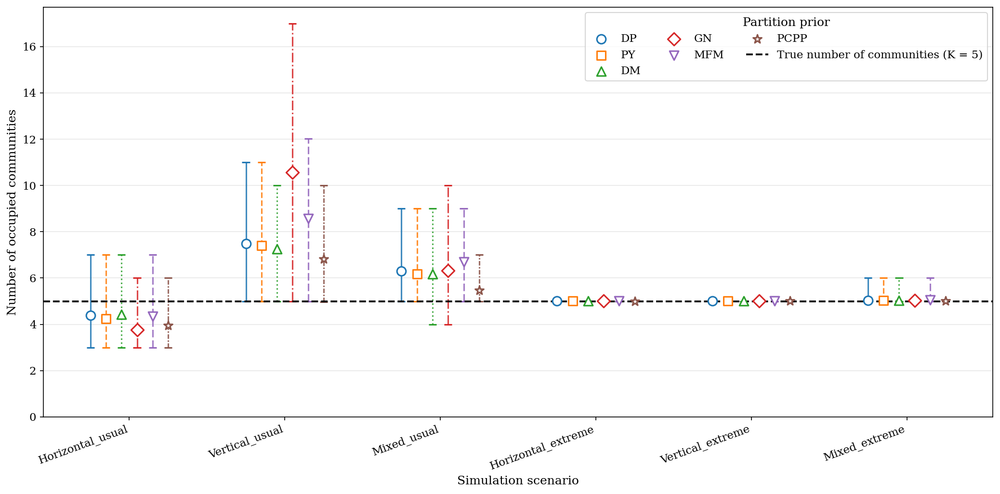

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define scenario and prior order
scenario_order = [
    "Horizontal_usual",
    "Vertical_usual",
    "Mixed_usual",
    "Horizontal_extreme",
    "Vertical_extreme",
    "Mixed_extreme"
]

prior_order = ["DP", "PY", "DM", "GN", "MFM", "PCPP"]

# Define colors for each prior
colors = {
    "DP": "#1f77b4",
    "PY": "#ff7f0e",
    "DM": "#2ca02c",
    "GN": "#d62728",
    "MFM": "#9467bd",
    "PCPP": "#8c564b"
}

# Define marker and line styles
markers = {
    "DP": "o",
    "PY": "s",
    "DM": "^",
    "GN": "D",
    "MFM": "v",
    "PCPP": "*"
}

linestyles = {
    "DP": "-",
    "PY": "--",
    "DM": ":",
    "GN": "-.",
    "MFM": (0, (5, 2)),
    "PCPP": (0, (3, 1, 1, 1))
}

# Create figure
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(scenario_order))
offsets = np.linspace(-0.25, 0.25, len(prior_order))

# Plot each prior
for i, prior in enumerate(prior_order):

    data = (
        df_summary[df_summary["Prior"] == prior]
        .set_index("Scenario")
        .reindex(scenario_order)
    )

    x_offset = x + offsets[i]
    color = colors[prior]

    # Plot mean values
    ax.scatter(
        x_offset,
        data["K_mean"],
        color=color,
        marker=markers[prior],
        s=80,
        facecolors="white",
        edgecolors=color,
        linewidths=1.5,
        label=prior,
        zorder=3
    )

    # Plot empirical 95% intervals
    ax.vlines(
        x_offset,
        data["K_CI_lower"],
        data["K_CI_upper"],
        color=color,
        linewidth=1.5,
        alpha=0.85,
        linestyles=linestyles[prior]
    )

    # Add horizontal caps
    cap_width = 0.025

    ax.hlines(
        data["K_CI_lower"],
        x_offset - cap_width,
        x_offset + cap_width,
        color=color,
        linewidth=1.5
    )

    ax.hlines(
        data["K_CI_upper"],
        x_offset - cap_width,
        x_offset + cap_width,
        color=color,
        linewidth=1.5
    )

# True number of communities
ax.axhline(
    y=5,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label="True number of communities (K = 5)",
    zorder=2
)

ax.set_ylim(bottom=0)

# Customize axes
ax.set_xticks(x)
ax.set_xticklabels(
    scenario_order,
    rotation=20,
    ha="right"
)

ax.set_xlabel("Simulation scenario", fontsize=12)
ax.set_ylabel("Number of occupied communities", fontsize=12)


# Legend
ax.legend(
    title="Partition prior",
    ncol=3,
    frameon=True
)

# Grid and layout
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "K_comparison_priors.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()